In [1]:
import pandas as pd
import matplotlib.pyplot as plt
plays = pd.read_csv('plays.csv')
print(plays.shape)
print(plays.head())

(40934, 51)
           game_id  play_id   game_date  week season_type home_team away_team  \
0  2025_01_DAL_PHI        1  2025-09-04     1     regular       PHI       DAL   
1  2025_01_DAL_PHI       40  2025-09-04     1     regular       PHI       DAL   
2  2025_01_DAL_PHI       71  2025-09-04     1     regular       PHI       DAL   
3  2025_01_DAL_PHI      112  2025-09-04     1     regular       PHI       DAL   
4  2025_01_DAL_PHI      141  2025-09-04     1     regular       PHI       DAL   

  posteam defteam  quarter  ... defteam_score  score_differential      ep  \
0     NaN     NaN        1  ...           NaN                 NaN  0.7702   
1     DAL     PHI        1  ...           0.0                 0.0  0.7702   
2     DAL     PHI        1  ...           0.0                 0.0  2.3052   
3     DAL     PHI        1  ...           0.0                 0.0  2.7085   
4     DAL     PHI        1  ...           0.0                 0.0  3.0221   

      epa      wp  home_wp     wpa    

In [2]:
fourth = plays[
    (plays['down'] == 4)
    & (plays['season_type'] == 'regular')
    & (plays['play_type'].isin(['pass','run','punt','field_goal']))
].copy()

In [3]:
fourth['decision']=fourth['play_type'].replace(
    {'pass':'go', 'run':'go', 'field_goal':'fg'}
)
fourth['decision'].value_counts()

,count
decision,
punt,1700
fg,850
go,772


In [4]:
zone = fourth[
    (fourth['yards_to_go'] <= 3)
    & (fourth['yardline_100'] <= 50)
].copy()
print(len(zone))
zone['decision'].value_counts()

521


,count
decision,
go,384
fg,120
punt,17


In [5]:
team = zone.groupby('posteam').agg(
    situations=('decision','size'),
    go_rate=('decision',lambda s:(s == 'go').mean()),
).reset_index()
team.sort_values('go_rate',ascending=False,).head(10)

,posteam,situations,go_rate
25,PHI,8,1.000000
10,DET,20,0.950000
31,WAS,15,0.933333
29,TB,14,0.928571
13,IND,20,0.900000
4,CAR,20,0.900000
3,BUF,18,0.888889
7,CLE,12,0.833333
9,DEN,12,0.833333
19,MIA,10,0.800000


In [6]:
go = zone[zone['decision'] == 'go'].copy()
go["converted"] = ((go["first_down"] == 1) | (go["touchdown"] == 1)).astype(int)

results = go.groupby('posteam').agg(
    attempts=('converted','size'),
    conv_rate=('converted','mean'),
    wpa=('wpa','sum'),
).reset_index()


In [7]:
final = team.merge(results, on='posteam', how='left')
final.sort_values('wpa',ascending=False)

,posteam,situations,go_rate,attempts,conv_rate,wpa
15,KC,20,0.800000,16,0.875000,1.0320
4,CAR,20,0.900000,18,0.722222,0.9253
21,NE,20,0.650000,13,0.846154,0.8694
11,GB,19,0.684211,13,0.769231,0.6138
25,PHI,8,1.000000,8,0.875000,0.5303
24,NYJ,11,0.636364,7,0.714286,0.4593
2,BAL,13,0.692308,9,0.666667,0.3965
7,CLE,12,0.833333,10,0.800000,0.3930
28,SF,18,0.666667,12,0.750000,0.3919
10,DET,20,0.950000,19,0.578947,0.2894


In [8]:
team_colors = {
    "ARI": "#97233F", "ATL": "#A71930", "BAL": "#241773", "BUF": "#00338D",
    "CAR": "#0085CA", "CHI": "#0B162A", "CIN": "#FB4F14", "CLE": "#FF3C00",
    "DAL": "#003594", "DEN": "#FB4F14", "DET": "#0076B6", "GB":  "#203731",
    "HOU": "#03202F", "IND": "#002C5F", "JAX": "#006778", "KC":  "#E31837",
    "LA":  "#003594", "LAC": "#0080C6", "LV":  "#000000", "MIA": "#008E97",
    "MIN": "#4F2683", "NE":  "#002244", "NO":  "#D3BC8D", "NYG": "#0B2265",
    "NYJ": "#125740", "PHI": "#004C54", "PIT": "#FFB612", "SEA": "#002244",
    "SF":  "#AA0000", "TB":  "#D50A0A", "TEN": "#4B92DB", "WAS": "#5A1414",
}

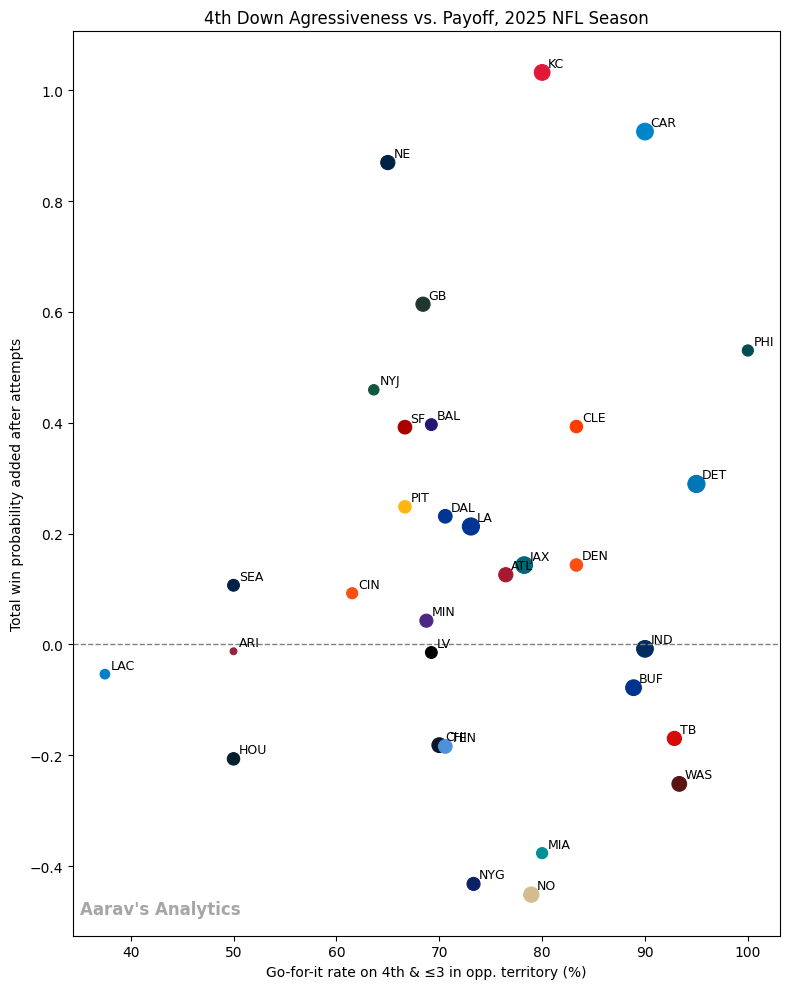

In [9]:
colors = final['posteam'].map(team_colors)
fix, ax = plt.subplots(figsize=(8,10))
ax.scatter(
    final['go_rate'] * 100,
    final['wpa'],
    c=colors,
    s=final['attempts'] * 8,
    #edgecolor="white",
    linewidth=0.8,
)

for _, row in final.iterrows():
  ax.annotate(row['posteam'], (row['go_rate'] * 100, row['wpa']),
              fontsize = 9, xytext=(4,4), textcoords="offset points")

ax.axhline(0, color="gray", linestyle ="--", linewidth=1)
ax.set_xlabel("Go-for-it rate on 4th & ≤3 in opp. territory (%)")
ax.set_ylabel("Total win probability added after attempts")
ax.set_title("4th Down Agressiveness vs. Payoff, 2025 NFL Season")

ax.text(
    0.01, 0.02,
    "Aarav's Analytics",
    transform=ax.transAxes,
    ha='left',va='bottom',
    fontsize=12, color='gray', alpha=0.7,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [10]:
league_go = (zone['decision'] == 'go').mean() * 100
league_conv = go['converted'].mean() * 100
print(league_go, league_conv)

73.70441458733205 61.458333333333336


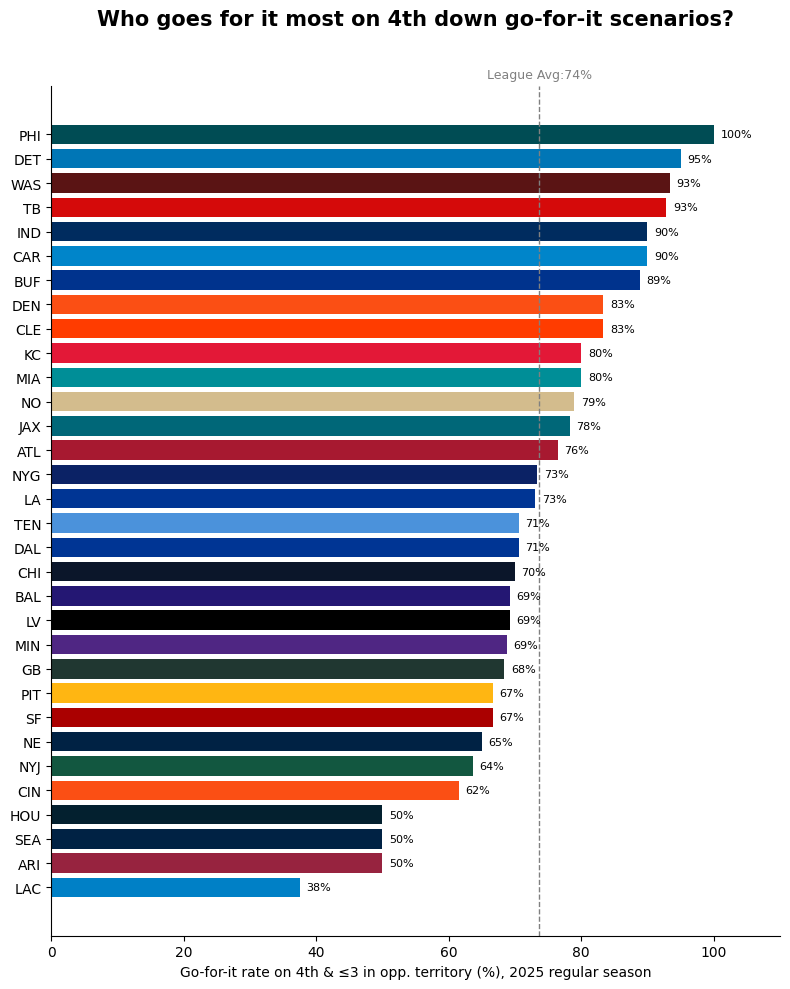

In [11]:
s = final.sort_values('go_rate')
fig, ax = plt.subplots(figsize=(8,10))
ax.barh(s['posteam'],s['go_rate']*100,color=s['posteam'].map(team_colors))
ax.axvline(league_go,color='gray',linestyle='--',linewidth=1)
ax.text(league_go,1.01,f"League Avg:{league_go:.0f}%", transform=ax.get_xaxis_transform(),ha='center',fontsize=9,color='gray')
for i,v in enumerate(s['go_rate']*100):
  ax.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8)

ax.set_xlim(0,110)
ax.spines[['top','right']].set_visible(False)
ax.set_title("Who goes for it most on 4th down go-for-it scenarios?",fontsize=15,fontweight='bold',loc='center',pad=44)
ax.set_xlabel("Go-for-it rate on 4th & ≤3 in opp. territory (%), 2025 regular season")

plt.tight_layout()
plt.show()

In [12]:
c = final.sort_values('conv_rate')
for i, (v,n) in enumerate(zip(c['conv_rate']*100,c['attempts'])):
  ax.text(v+1, i, f"{v:0f}% ({n})", va='center',fontsize=8)

In [17]:
def bar_chart(plays,col,title,subtitle,league_value,fname,show_attempts=False):
  d = plays.sort_values(col)
  fig, ax = plt.subplots(figsize=(8,10))
  ax.barh(d['posteam'], d[col]*100, color=d['posteam'].map(team_colors))

  ax.axvline(league_value,color='gray',linestyle='--',linewidth=1)
  ax.text(league_value,1.01,f"League avg:{league_value:.0f}%",transform=ax.get_xaxis_transform(), ha="center", fontsize=9, color="gray")

  for i, (v,n) in enumerate(zip(d[col]*100,d['attempts'])):
    label = f"{v:.0f}% ({n})" if show_attempts else f"{v:.0f}%"
    ax.text(v+1,i,label,va='center',fontsize=8)

  ax.set_xlim(0,110)
  ax.spines[['top','right']].set_visible(False)
  ax.set_title(title, fontsize=15, fontweight='bold', loc='left', pad=44)
  ax.text(0,1.045, subtitle, transform=ax.transAxes, fontsize=10, color='gray')
  ax.text(0.99,0.02, "Aarav's Analytics", transform=ax.transAxes, ha='right',va='bottom',fontsize=12,color='gray', alpha=0.7,fontweight='bold')

  plt.tight_layout()
  plt.show()

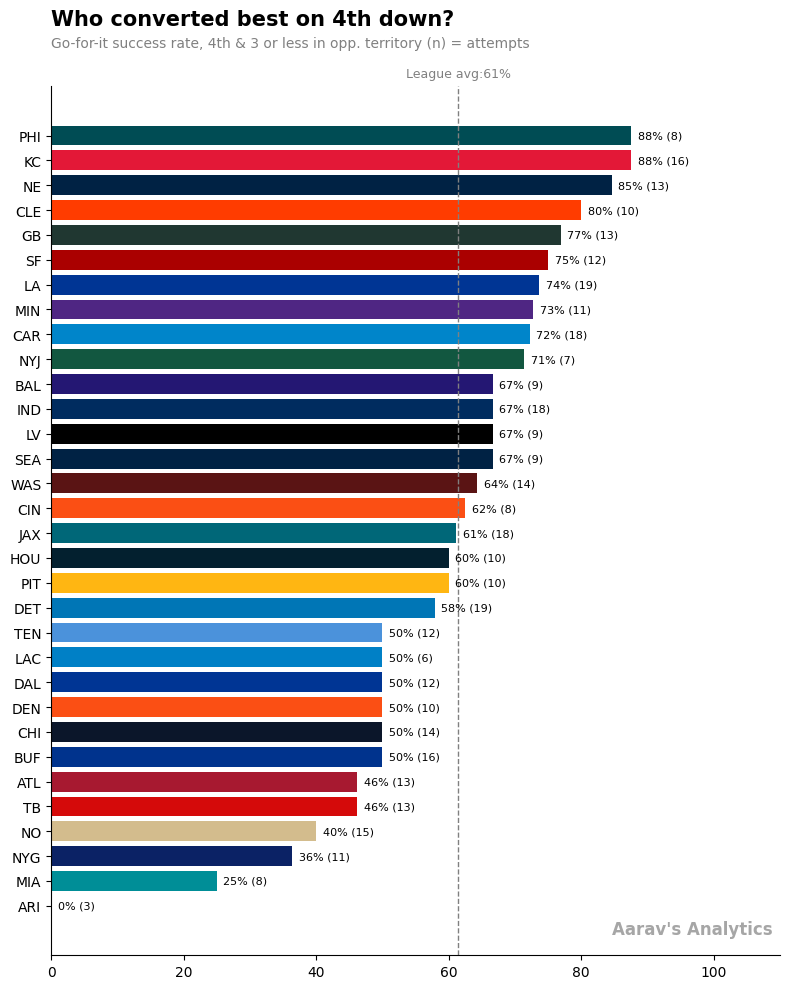

In [19]:
bar_chart(final, "conv_rate", "Who converted best on 4th down?",
          "Go-for-it success rate, 4th & 3 or less in opp. territory (n) = attempts",
          league_conv, "conv_rate.png", show_attempts=True)